# Stored Procedures, Functions, and Triggers

Code can also run **inside** the database. **Functions** compute values, **procedures** run multi-step jobs with transaction control, and **triggers** run code automatically when rows change. Used with care, they enforce rules for every application that writes to the database.

**After this lesson you can:**

1. Write SQL and PL/pgSQL functions.
2. Write a procedure that commits in batches.
3. Use triggers for timestamps, audit logs and validation.
4. Measure the cost of triggers and decide when logic belongs in the database.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

lab = create_engine(datasets.POSTGRES_URL.format(db="course"))   # a separate database for experiments

def run(sql: str) -> None:
    """Execute SQL statements (DDL/DML) in the lab database, in one transaction."""
    with lab.begin() as conn:
        if "$$" in sql:                       # function bodies contain ";" -> send the whole script at once
            conn.execute(text(sql))
            return
        for stmt in [s for s in sql.split(";") if s.strip()]:
            conn.execute(text(stmt))

def lq(sql: str, **params) -> pd.DataFrame:
    with lab.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. Functions

| Language | Use |
| :--- | :--- |
| `LANGUAGE sql` | one query; the planner can inline it |
| `LANGUAGE plpgsql` | variables, `IF`, loops, exceptions |

**Volatility** tells the planner how the function behaves: `IMMUTABLE` (same input → same output, always), `STABLE` (same within one query), `VOLATILE` (can change at any time, the default).

In [2]:
run("""
CREATE OR REPLACE FUNCTION net_price(gross numeric, vat_rate numeric DEFAULT 0.20)
RETURNS numeric LANGUAGE sql IMMUTABLE AS $$ SELECT round(gross / (1 + vat_rate), 2) $$;

CREATE OR REPLACE FUNCTION customer_tier(spend numeric)
RETURNS text LANGUAGE plpgsql IMMUTABLE AS $$
BEGIN
    IF spend IS NULL THEN RETURN 'none';
    ELSIF spend >= 45 THEN RETURN 'gold';
    ELSIF spend >= 38 THEN RETURN 'silver';
    ELSE RETURN 'bronze';
    END IF;
END $$
""")
print(lq("SELECT net_price(12) AS net_of_12, net_price(12, 0.08) AS net_at_8pct"))

   net_of_12  net_at_8pct
0       10.0        11.11


The functions live in the lab database. To use them on Chinook data, the cell copies the customer spend into the lab database first.

In [3]:
q("SELECT customer_id, sum(total) AS spend FROM invoice GROUP BY 1").to_sql("customer_spend", lab, if_exists="replace", index=False)
tiers = lq("SELECT customer_tier(spend::numeric) AS tier, count(*) AS customers, min(spend), max(spend) FROM customer_spend GROUP BY 1 ORDER BY 3")
tiers

,tier,customers,min,max
0,bronze,31,36.64,37.62
1,silver,23,38.62,43.62
2,gold,5,45.62,49.62


## 2. Procedures with Transaction Control

A **procedure** (`CREATE PROCEDURE`, called with `CALL`) can `COMMIT` inside its body. That is useful for long batch jobs: committing every *n* rows keeps locks short and avoids losing all work if the job fails near the end.

In [4]:
run("""
DROP TABLE IF EXISTS raw_events, clean_events;
CREATE TABLE raw_events AS
    SELECT g AS id, CASE WHEN g % 50 = 0 THEN NULL ELSE (random() * 100)::int END AS value FROM generate_series(1, 100000) g;
CREATE TABLE clean_events (id int PRIMARY KEY, value int NOT NULL);
DROP TABLE IF EXISTS batch_log;
CREATE TABLE batch_log (batch int, rows_moved int, at timestamptz DEFAULT clock_timestamp());

CREATE OR REPLACE PROCEDURE move_clean_events(batch_size int) LANGUAGE plpgsql AS $$
DECLARE
    last_id int := 0; moved int; batch_no int := 0;
BEGIN
    LOOP
        INSERT INTO clean_events
            SELECT id, value FROM raw_events WHERE id > last_id AND id <= last_id + batch_size AND value IS NOT NULL;
        GET DIAGNOSTICS moved = ROW_COUNT;
        EXIT WHEN last_id >= (SELECT max(id) FROM raw_events);
        batch_no := batch_no + 1;
        INSERT INTO batch_log (batch, rows_moved) VALUES (batch_no, moved);
        last_id := last_id + batch_size;
        COMMIT;                                        -- each batch is durable on its own
    END LOOP;
END $$
""")
with lab.connect().execution_options(isolation_level="AUTOCOMMIT") as conn:
    conn.execute(text("CALL move_clean_events(20000)"))
print(lq("SELECT count(*) AS clean_rows FROM clean_events"))
lq("SELECT batch, rows_moved FROM batch_log ORDER BY batch")

   clean_rows
0       98000


,batch,rows_moved
0,1,19600
1,2,19600
2,3,19600
3,4,19600
4,5,19600


A procedure that commits must be called outside an explicit transaction, so the cell uses an autocommit connection. Every 50th raw row had a NULL value and was skipped: 100,000 − 2,000 = 98,000 clean rows.

## 3. Triggers

A **trigger** calls a function `BEFORE` or `AFTER` an `INSERT`, `UPDATE` or `DELETE`, once per row (`FOR EACH ROW`) or once per statement. In the trigger function, `NEW` is the new row and `OLD` is the old row.

Three classic triggers:

1. **`updated_at`**: set a timestamp on every change.
2. **audit log**: record who changed what, and the old and new values.
3. **validation**: reject changes that break a business rule that a `CHECK` cannot express.

In [5]:
run("""
DROP TABLE IF EXISTS price_audit, product CASCADE;
CREATE TABLE product (id int PRIMARY KEY, name text, price numeric(8,2), updated_at timestamptz DEFAULT now());
CREATE TABLE price_audit (product_id int, old_price numeric, new_price numeric, changed_by text, changed_at timestamptz);

CREATE OR REPLACE FUNCTION touch_updated_at() RETURNS trigger LANGUAGE plpgsql AS $$
BEGIN NEW.updated_at := clock_timestamp(); RETURN NEW; END $$;

CREATE OR REPLACE FUNCTION audit_price() RETURNS trigger LANGUAGE plpgsql AS $$
BEGIN
    IF NEW.price IS DISTINCT FROM OLD.price THEN
        INSERT INTO price_audit VALUES (OLD.id, OLD.price, NEW.price, current_user, clock_timestamp());
    END IF;
    RETURN NEW;
END $$;

CREATE OR REPLACE FUNCTION limit_price_change() RETURNS trigger LANGUAGE plpgsql AS $$
BEGIN
    IF NEW.price > OLD.price * 1.5 THEN
        RAISE EXCEPTION 'price of % cannot rise more than 50%% in one step (% -> %)', OLD.name, OLD.price, NEW.price;
    END IF;
    RETURN NEW;
END $$;

CREATE TRIGGER a_validate BEFORE UPDATE ON product FOR EACH ROW EXECUTE FUNCTION limit_price_change();
CREATE TRIGGER b_touch BEFORE UPDATE ON product FOR EACH ROW EXECUTE FUNCTION touch_updated_at();
CREATE TRIGGER c_audit AFTER UPDATE ON product FOR EACH ROW EXECUTE FUNCTION audit_price();
INSERT INTO product VALUES (1, 'Vinyl LP', 20, now() - interval '1 day'), (2, 'Headphones', 80, now() - interval '1 day')
""")
run("UPDATE product SET price = 24 WHERE id = 1")
run("UPDATE product SET name = 'Headphones Pro' WHERE id = 2")                # no price change, no audit row
try:
    run("UPDATE product SET price = 200 WHERE id = 2")
except Exception as err:
    print("rejected:", str(err.orig).splitlines()[0])
print(lq("SELECT id, name, price, updated_at > now() - interval '1 minute' AS updated_recently FROM product ORDER BY id"))
lq("SELECT product_id, old_price, new_price, changed_by FROM price_audit")

rejected: price of Headphones Pro cannot rise more than 50% in one step (80.00 -> 200.00)
   id            name  price  updated_recently
0   1        Vinyl LP   24.0              True
1   2  Headphones Pro   80.0              True


,product_id,old_price,new_price,changed_by
0,1,20.0,24.0,course


PostgreSQL fires triggers of the same kind in **alphabetical order** of their names, which is why the names start with `a_`, `b_`, `c_`.

## 4. The Cost of Triggers

Row-level triggers run once per row. The experiment updates 100,000 rows with and without the three triggers.

{'no triggers': '1.08 s', '3 row triggers': '2.87 s'} | audit rows: 100000


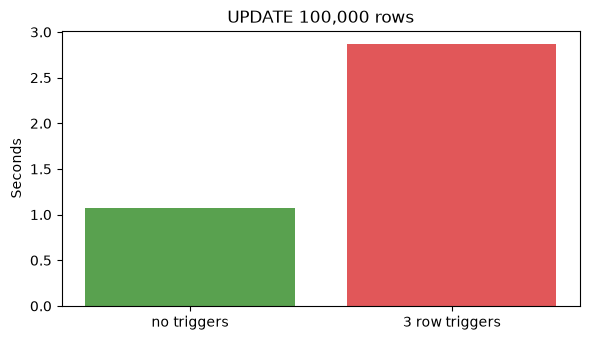

In [6]:
import time

def bulk_update(with_triggers: bool) -> float:
    run("TRUNCATE product, price_audit; "
        "INSERT INTO product SELECT g, 'item ' || g, 10 + g % 50, now() FROM generate_series(1, 100000) g")
    run(f"ALTER TABLE product {'ENABLE' if with_triggers else 'DISABLE'} TRIGGER USER")
    t = time.perf_counter()
    run("UPDATE product SET price = price * 1.1")
    return time.perf_counter() - t

cost = {"no triggers": bulk_update(False), "3 row triggers": bulk_update(True)}
run("ALTER TABLE product ENABLE TRIGGER USER")
print({k: f"{v:.2f} s" for k, v in cost.items()}, "| audit rows:", lq("SELECT count(*) AS n FROM price_audit")["n"][0])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(cost.keys(), cost.values(), color=["#59A14F", "#E15759"])
ax.set(title="UPDATE 100,000 rows", ylabel="Seconds")
plt.tight_layout()
plt.show()

## 5. When to Put Logic in the Database

| Put it in the database | Keep it in the application |
| :--- | :--- |
| data integrity rules that every writer must obey | business workflows that change often |
| audit trails that must not be bypassed | calls to external services (e-mail, APIs) |
| set-based batch jobs close to the data | complex logic that needs unit tests and code review |

Hidden logic is the main risk: a developer runs an `UPDATE` and does not know that three triggers fire. Keep triggers small, name them clearly, version them in migrations, and document them.

*Insight: Use triggers and functions for rules that must hold for every writer (timestamps, audits, invariants), and keep business workflows in application code where they are visible, testable and easy to change.*

## Real-World Use Case or Analogy

A trigger is like a **motion-sensor light**: nobody has to remember to switch it on, it reacts every time somebody walks in. That is useful for safety, and annoying if nobody knows it exists and it starts the alarm system too.

Banks and healthcare systems use audit triggers to satisfy regulators. Data engineers use them for change data capture in older systems, although logical replication and tools such as Debezium (M12) have largely replaced trigger-based CDC.